# 16. When spectral methods fail, and what to do about it

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/16_when_spectral_methods_fail.ipynb)

*Goes beyond L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000), using the tools built in notebooks 1 to 14.*

The earlier notebooks show spectral methods at their best: a few dozen points, a dozen correct
digits. They earn that accuracy from smooth solutions on simple domains, and they lose it, or
fail outright, when those conditions are not met. This notebook collects the failures.

- nine ways in which a spectral computation goes wrong, eight of them reproduced in a few lines,
  and one limit that no resolution removes (geometry)
- the cause of each, the diagnostic that reveals it, and the repair where one exists
- a guide to choosing between spectral, finite difference and finite element methods
- a checklist for debugging a spectral computation

Start from the symptom:

| Symptom | Likely cause | Section |
| --- | --- | --- |
| error falls like $N^{-2}$ or slower, not geometrically | kink or jump in the data or coefficients | 16.1 |
| large errors near the ends of a periodic grid | the function is not periodic | 16.2 |
| grid-scale wiggles in the solution | a thin layer is under-resolved | 16.3 |
| a nonlinear run blows up, or its "conserved" quantities drift | aliasing | 16.4 (drift of invariants: notebook 15) |
| error rises again as $N$ grows | rounding errors, ill-conditioning | 16.5 |
| an explicit time integration needs absurdly small steps, or explodes | stiffness of the spectral operator | 16.6 |
| convergence is good but stalls short of geometric | corner singularity | 16.7 |
| eigenvalues that move when $N$ changes | modes that the grid cannot resolve | 16.8 |
| smooth, plausible, wrong | bookkeeping: ordering, scaling, Nyquist | 16.9 |
| the domain is not a box, a disk or a periodic cell | geometry | 16.10 |

The guide to choosing a method is in 16.10 and the debugging checklist in 16.11.

**Worked examples:** eight short ones, each a failure with its diagnosis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct, fft, ifft
from scipy.linalg import solve, solve_banded, eigvals

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# cheb(N) from notebook 5, fft_derivative from notebook 2, cheb_coeffs from notebook 7, clenshaw_curtis from notebook 10
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

def fft_derivative(v, order=1):
    """Spectral derivative of real periodic samples v on the grid 2πj/N; the Nyquist mode is zeroed for odd orders."""
    N = len(v)
    k = np.fft.fftfreq(N, d=1 / N)
    factor = (1j * k) ** order
    if order % 2 and N % 2 == 0:
        factor[N // 2] = 0
    return np.real(np.fft.ifft(factor * np.fft.fft(v)))

def cheb_coeffs(values):
    """Chebyshev coefficients a_k of the degree-N interpolant through values at the Chebyshev points."""
    values = np.asarray(values, dtype=float)
    N = len(values) - 1
    if N == 0:
        return values.copy()
    a = dct(values, type=1) / N
    a[0] /= 2
    a[N] /= 2
    return a

def clenshaw_curtis(N):
    """Clenshaw-Curtis nodes (the Chebyshev points) and weights on [-1, 1]."""
    if N == 0:
        return np.ones(1), np.array([2.0])
    x = np.cos(np.pi * np.arange(N + 1) / N)
    moments = np.zeros(N + 1)
    even = np.arange(0, N + 1, 2)
    moments[even] = 2 / (1 - even.astype(float) ** 2)
    w = dct(moments, type=1) / N
    w[0] /= 2
    w[N] /= 2
    return x, w

def observed_order(N, error):
    """Slope of log(error) against log(N), with the sign changed: the algebraic order of convergence."""
    return -np.polyfit(np.log(N), np.log(error), 1)[0]

## 16.1 A jump in the data

**Problem.** A rod loses heat to the surrounding air along its length, and both ends are held
at the air temperature. An electric heater is wrapped around the right half only. In
dimensionless form the temperature excess obeys

$$\theta'' - m^2\theta = -q(x),\qquad q(x) = \begin{cases} 0, & x < 0\\ 1, & x > 0 \end{cases},\qquad \theta(\pm1) = 0,$$

with $m = 2$. The source jumps at $x = 0$, so $\theta''$ jumps there, while $\theta$ and
$\theta'$ are continuous.

**By hand.** On each half the equation has constant coefficients:
$\theta = A\sinh m(x + 1)$ on the left, and
$\theta = \tfrac{1}{m^2}\big[1 - \cosh m(1 - x)\big] + B\sinh m(1 - x)$ on the right. Both
satisfy the end conditions. Continuity of $\theta$ and $\theta'$ at $x = 0$ gives two linear
equations for $A$ and $B$.

In [3]:
m_rod = 2.0

def rod_exact(x):
    s, c = np.sinh(m_rod), np.cosh(m_rod)
    A, B = np.linalg.solve([[s, -s], [m_rod * c, m_rod * c]], [(1 - c) / m_rod**2, s / m_rod])
    left = A * np.sinh(m_rod * (x + 1))
    right = (1 - np.cosh(m_rod * (1 - x))) / m_rod**2 + B * np.sinh(m_rod * (1 - x))
    return np.where(x < 0, left, right)

def rod_one_domain(N, exact_midpoint=False):
    """One Chebyshev grid on [-1, 1]; the source is sampled at the grid points (meant to be ½ at the jump itself)."""
    D, x = cheb(N)
    if exact_midpoint and N % 2 == 0:
        x[N // 2] = 0.0                                   # see the discussion below the plot
    L = D @ D - m_rod**2 * np.eye(N + 1)
    source = np.where(x > 0, 1.0, np.where(x < 0, 0.0, 0.5))
    theta = np.zeros(N + 1)
    theta[1:-1] = solve(L[1:-1, 1:-1], -source[1:-1])
    return x, theta

**The fix: split the domain at the jump.** Use one Chebyshev grid on $[-1, 0]$ and another on
$[0, 1]$. On each piece the solution is smooth, in fact analytic. The two pieces are joined by
the two conditions that the physics supplies, continuity of temperature and of heat flux. In
the matrix, these replace the two rows that belong to the shared point. This is a spectral
method with two **elements**.

the middle point of the grid for N = 8 is x = 6.1e-17, so the test x > 0 is True
one domain, observed order for N >= 32: 0.98 for N even as computed, 1.92 for N even with the middle point set to 0, 1.89 for N odd
257 points: error 1.5e-03 as computed, 6.6e-06 with the middle point set to 0       two elements, 2 x 17 points: error 4.3e-15


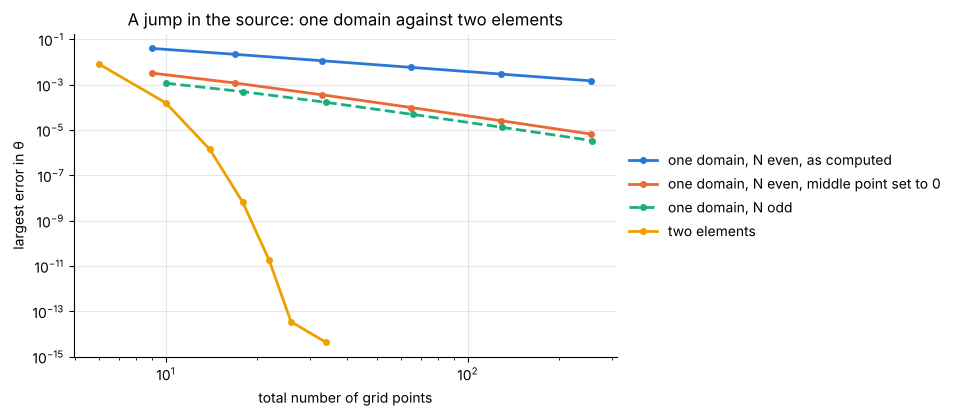

In [4]:
def rod_two_elements(N):
    """Two Chebyshev grids of N + 1 points each, [0, 1] (stored first) and [-1, 0], joined at x = 0."""
    D, xi = cheb(N)
    D = 2 * D                                             # each element has length 1: d/dx = 2 d/dξ
    x_right, x_left = (xi + 1) / 2, (xi - 1) / 2          # index 0 is the right end of each element
    L = D @ D - m_rod**2 * np.eye(N + 1)
    n = N + 1
    A, b = np.zeros((2 * n, 2 * n)), np.zeros(2 * n)
    A[:n, :n], A[n:, n:] = L, L
    b[:n] = -1.0                                          # the heater covers the right element only
    A[0, :], A[0, 0], b[0] = 0, 1, 0                      # θ = 0 at x = +1 (first point of the right element)
    A[-1, :], A[-1, -1], b[-1] = 0, 1, 0                  # θ = 0 at x = -1 (last point of the left element)
    A[N, :], A[N, N], A[N, n], b[N] = 0, 1, -1, 0         # θ continuous at x = 0
    A[n, :], b[n] = 0, 0
    A[n, :n], A[n, n:] = D[N], -D[0]                      # θ' continuous at x = 0
    return np.r_[x_right, x_left], solve(A, b)

def largest_error(solver, N_values, **options):
    return np.array([np.abs(theta - rod_exact(x)).max() for x, theta in (solver(N, **options) for N in N_values)])

even_N = np.array([8, 16, 32, 64, 128, 256])
odd_N = even_N + 1
element_N = np.array([2, 4, 6, 8, 10, 12, 16])
error_even, error_odd = largest_error(rod_one_domain, even_N), largest_error(rod_one_domain, odd_N)
error_repaired = largest_error(rod_one_domain, even_N, exact_midpoint=True)
error_split = largest_error(rod_two_elements, element_N)

order_even, order_odd, order_repaired = (observed_order(N[2:], e[2:]) for N, e in
                                         ((even_N, error_even), (odd_N, error_odd), (even_N, error_repaired)))
x_mid = cheb(8)[1][4]
print(f"the middle point of the grid for N = 8 is x = {x_mid:.1e}, so the test x > 0 is {x_mid > 0}")
print(f"one domain, observed order for N >= 32: {order_even:.2f} for N even as computed, {order_repaired:.2f} for N even with"
      f" the middle point set to 0, {order_odd:.2f} for N odd")
print(f"257 points: error {error_even[-1]:.1e} as computed, {error_repaired[-1]:.1e} with the middle point set to 0"
      f"       two elements, 2 x 17 points: error {error_split[-1]:.1e}")
assert 0 < x_mid < 1e-16                                              # cos(π/2) is not exactly zero in floating point
assert abs(order_even - 1) < 0.1 and abs(order_odd - 2) < 0.15 and abs(order_repaired - 2) < 0.15
assert error_split[-1] < 1e-12 and error_even[-1] > 100 * error_repaired[-1] > 1e-6

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.loglog(even_N + 1, error_even, "o-", ms=4, label="one domain, N even, as computed")
ax.loglog(even_N + 1, error_repaired, "o-", ms=4, label="one domain, N even, middle point set to 0")
ax.loglog(odd_N + 1, error_odd, "o--", ms=4, label="one domain, N odd")
ax.loglog(2 * (element_N + 1), np.maximum(error_split, 1e-16), "o-", ms=4, label="two elements")
ax.set(xlabel="total number of grid points", ylabel="largest error in θ", title="A jump in the source: one domain against two elements")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

With one domain the convergence is algebraic. The error falls like $N^{-2}$ at best, no better
than a second-order finite difference method, at the price of a dense matrix. With the domain
split at the jump, 34 points give rounding-level accuracy.

The top curve is a lesson of another kind. `rod_one_domain` was written to use the mean value
$\tfrac12$ of the source at a grid point that sits on the jump, and as written it never does.
For even $N$ the middle point is $\cos(\pi/2)$, which in floating-point arithmetic is
$6\times10^{-17}$ and not 0. The test `x > 0` therefore puts that point on the heated side, the
source there is 1, and this one value out of $N + 1$ lowers the order from 2 to 1: with 257
points the error is $1.5\times10^{-3}$ where $6.6\times10^{-6}$ was available. Setting the
middle point to exactly 0 (the argument `exact_midpoint`) restores $N^{-2}$. Nothing in the
output gives the mistake away. Section 16.9 collects more of this kind.

The rule: a spectral method converges geometrically only where the solution is smooth
**inside** each grid. Put element boundaries wherever the data, the coefficients or the
geometry change abruptly (a change of material, the edge of a heater, a step in a load).
If the location of the kink is unknown or moves, as a shock or a phase front does, this is
hard to do, and a lower-order method is usually the better tool.

## 16.2 A non-periodic function on a Fourier grid

**Problem.** The temperature along a rod is $u(x) = e^{-x/2}$ for $0 \le x < 2\pi$. Someone
differentiates it with `fft_derivative`, which worked so well in notebook 2.

A Fourier method differentiates the **periodic extension** of the data. For this function the
extension jumps from $e^{-\pi} \approx 0.04$ back to 1 at every period, like the sawtooth
$u = x$ in the exercises of notebook 1. The method sees a discontinuity, and its derivative is
a spike.

   N    Fourier: largest error   error at the midpoint
  16             1.93              2.3e-02
  64             7.00              5.9e-03
 256            27.26              1.5e-03
Chebyshev grid with 17 points: largest error 3.6e-15


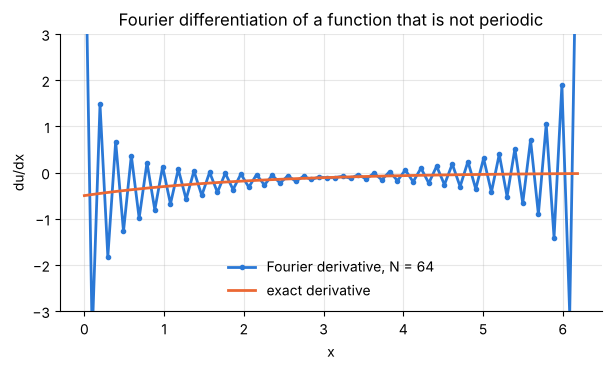

In [5]:
profile = lambda x: np.exp(-x / 2)
slope = lambda x: -0.5 * np.exp(-x / 2)

print("   N    Fourier: largest error   error at the midpoint")
fourier_max, fourier_mid = [], []
for N in (16, 64, 256):
    x = 2 * np.pi * np.arange(N) / N
    error = np.abs(fft_derivative(profile(x)) - slope(x))
    fourier_max.append(error.max())
    fourier_mid.append(error[N // 2])
    print(f"{N:4d}   {error.max():14.2f}   {error[N // 2]:18.1e}")

D, xi = cheb(16)                                          # the fix: a Chebyshev grid mapped to [0, 2π]
x_cheb = np.pi * (xi + 1)
error_cheb = np.abs((D / np.pi) @ profile(x_cheb) - slope(x_cheb)).max()
print(f"Chebyshev grid with 17 points: largest error {error_cheb:.1e}")
assert fourier_max[-1] > 10 * fourier_max[0] and fourier_mid[-1] > 1e-4      # worse at the ends, slow in the middle
assert error_cheb < 1e-12

N = 64
x = 2 * np.pi * np.arange(N) / N
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(x, fft_derivative(profile(x)), "o-", ms=3, label="Fourier derivative, N = 64")
ax.plot(x, slope(x), label="exact derivative")
ax.set(xlabel="x", ylabel="du/dx", ylim=(-3, 3), title="Fourier differentiation of a function that is not periodic")
ax.legend(frameon=False, loc="lower center");

The error at the ends **grows** in proportion to $N$, and the oscillations it sends into the
interior decay only like $1/N$. These are the Gibbs oscillations of notebook 3, made worse by
the differentiation. More points make the ends worse and the interior better only slowly.
Seventeen Chebyshev points do the job to fourteen digits, because polynomial interpolation
asks nothing of the function at the ends of the interval.

Periodic in every derivative is a strong requirement. A function that merely returns to the
same value, with a different slope, is still not periodic enough: the convergence is then
algebraic (notebook 3). Use Fourier methods for problems that are periodic by nature (angles,
closed curves, flows in periodic boxes) and Chebyshev methods otherwise.

## 16.3 An under-resolved boundary layer

**Problem.** A convection–diffusion balance with weak diffusion,

$$\varepsilon u'' + u' = 1,\qquad u(-1) = u(1) = 0 .$$

**By hand.** Away from the walls diffusion is negligible and $u' = 1$, so $u \approx x - 1$,
which satisfies the condition at $x = 1$. It misses the condition at $x = -1$ by 2, and a
**boundary layer** of thickness $\varepsilon$ makes the correction. The exact solution is

$$u(x) = x + 1 - B\,\big(1 - e^{-(x + 1)/\varepsilon}\big),\qquad B = \frac{2}{1 - e^{-2/\varepsilon}} .$$

With $\varepsilon = 0.01$ the layer occupies half a per cent of the interval.

N =  16:  last coefficients / largest = 3e-01    actual error = 3e-01
N =  32:  last coefficients / largest = 3e-03    actual error = 3e-03
N =  64:  last coefficients / largest = 1e-09    actual error = 5e-10


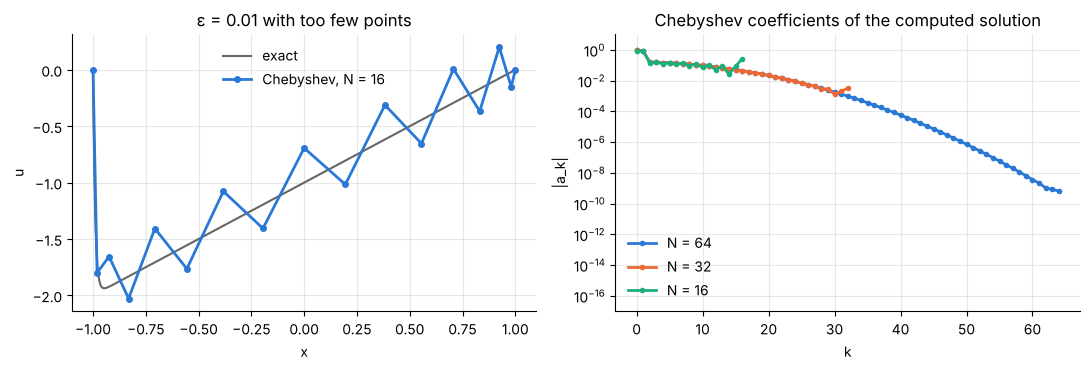

In [6]:
def layer_exact(x, eps):
    B = 2 / (1 - np.exp(-2 / eps))
    return x + 1 - B * (1 - np.exp(-(x + 1) / eps))

def layer_cheb(N, eps):
    D, x = cheb(N)
    L = eps * D @ D + D
    u = np.zeros(N + 1)
    u[1:-1] = solve(L[1:-1, 1:-1], np.ones(N - 1))
    return x, u

def layer_fd(N, eps):
    """Second-order centred differences on N equal intervals (a tridiagonal system)."""
    x, h = np.linspace(-1, 1, N + 1), 2 / N
    bands = np.zeros((3, N - 1))
    bands[0, 1:], bands[1, :], bands[2, :-1] = eps / h**2 + 1 / (2 * h), -2 * eps / h**2, eps / h**2 - 1 / (2 * h)
    u = np.zeros(N + 1)
    u[1:-1] = solve_banded((1, 1), bands, np.ones(N - 1))
    return x, u

eps = 0.01
fine = np.linspace(-1, 1, 2001)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x, u = layer_cheb(16, eps)
axes[0].plot(fine, layer_exact(fine, eps), color="0.4", lw=1.5, label="exact")
axes[0].plot(x, u, "o-", ms=4, label="Chebyshev, N = 16")
axes[0].set(xlabel="x", ylabel="u", title="ε = 0.01 with too few points")
axes[0].legend(frameon=False, loc="upper center")
tails = {}
for N in (64, 32, 16):                                           # the longest series first, so that the others stay visible
    x, u = layer_cheb(N, eps)
    a = np.abs(cheb_coeffs(u))
    tails[N] = (a[-3:].max() / a.max(), np.abs(u - layer_exact(x, eps)).max())
    axes[1].semilogy(np.maximum(a, 1e-18), "o-", ms=3, label=f"N = {N}")
axes[1].set(xlabel="k", ylabel="|a_k|", ylim=(1e-17, 10), title="Chebyshev coefficients of the computed solution")
axes[1].legend(frameon=False, loc="lower left")
fig.tight_layout()

for N, (tail, error) in sorted(tails.items()):
    print(f"N = {N:3d}:  last coefficients / largest = {tail:.0e}    actual error = {error:.0e}")
assert tails[16][1] > 0.1 and tails[16][0] > 0.1               # N = 16 fails, and its coefficients say so
assert tails[64][1] < 1e-8 and tails[64][0] < 1e-8             # N = 64 succeeds, and its coefficients say so

With $N = 16$ the computed solution oscillates across the whole interval, far from the layer
that causes the trouble: a global method spreads a local failure everywhere.

**The diagnostic** needs no exact solution. The Chebyshev coefficients of a resolved solution
fall to the rounding level (notebook 7). For $N = 16$ they do not decay at all, for $N = 32$
they stop at $10^{-3}$, for $N = 64$ they reach $10^{-9}$. In each case the size of the last
coefficients is a fair estimate of the actual error. The Fourier version of the same test
exposed the under-resolved Burgers shock in notebook 11.

**How many points?** Here the Chebyshev grid has an advantage. Its spacing next to the wall is
about $\pi^2/(2N^2)$ (notebook 4), so a layer of thickness $\varepsilon$ is resolved when $N$
is a modest multiple of $1/\sqrt\varepsilon$. A uniform grid needs a spacing of order
$\varepsilon$, so $N$ of order $1/\varepsilon$. Measure both: the smallest $N$ that gives an
error below $10^{-3}$, for the Chebyshev method and for centred finite differences.

In [7]:
def points_needed(solver, eps, candidates, tol=1e-3):
    for N in candidates:
        x, u = solver(N, eps)
        if np.abs(u - layer_exact(x, eps)).max() < tol:
            return N

eps_values = np.array([0.1, 0.03, 0.01, 0.003, 0.001])
N_cheb = np.array([points_needed(layer_cheb, e, range(4, 200, 2)) for e in eps_values])
N_fd = np.array([points_needed(layer_fd, e, np.unique(np.geomspace(10, 40000, 150).astype(int))) for e in eps_values])
power_cheb, power_fd = observed_order(eps_values, N_cheb), observed_order(eps_values, N_fd)      # N ∝ ε^(−power)

print("    ε      Chebyshev N   finite difference N")
for e, a, b in zip(eps_values, N_cheb, N_fd):
    print(f"{e:7.3f}  {a:10d}  {b:15d}")
print(f"fitted: N proportional to ε^(-{power_cheb:.2f}) for Chebyshev, ε^(-{power_fd:.2f}) for finite differences")
print(f"Chebyshev: N √ε = {np.round(N_cheb * np.sqrt(eps_values), 1)}")
assert abs(power_cheb - 0.5) < 0.05 and abs(power_fd - 1.0) < 0.05

    ε      Chebyshev N   finite difference N
  0.100          12              161
  0.030          22              550
  0.010          36             1584
  0.003          66             5392
  0.001         112            16415
fitted: N proportional to ε^(-0.48) for Chebyshev, ε^(-1.00) for finite differences
Chebyshev: N √ε = [3.8 3.8 3.6 3.6 3.5]


The scalings are $\varepsilon^{-1/2}$ and $\varepsilon^{-1}$ as predicted, and for this
tolerance the Chebyshev rule is $N \approx 3.6/\sqrt\varepsilon$. A layer a thousand times
thinner than the domain costs 112 Chebyshev points against 16 000 uniform ones.

Two limits to this good news. The clustering helps only layers **at the ends** of the grid: a
thin layer in the interior (a flame front, a shear layer, a shock) meets the coarsest part of
a Chebyshev grid and costs $N \sim 1/\varepsilon$, as on a Fourier grid. And for very small
$\varepsilon$ even $\varepsilon^{-1/2}$ becomes large. The remedies are then a coordinate
mapping that concentrates points where they are needed, or elements as in 16.1, with a small
element covering the layer.

## 16.4 Aliasing instability

**Problem.** Viscous Burgers flow, $u_t + u\,u_x = \nu u_{xx}$, periodic, from $u = \sin x$,
with $\nu = 0.005$ (notebook 11). The solution steepens into a front of thickness about
$4\nu/U$, with $U$ the speed on either side of it (notebook 11), which needs a thousand Fourier
modes or more. Run it with $N = 64$, which is far too few,
twice: with the nonlinear term computed directly on the grid, and with the 2/3 rule
(multiply $\widehat{u u_x}$ by a mask that keeps $|k| < N/3$; notebook 15 explains why this
removes the aliasing error of a quadratic term).

N = 64 without dealiasing: stopped at t = 3.66 with max |u| = 4.1e+03
N = 64 with the 2/3 rule:  reached t = 4.00, largest |u| during the run 1.26, error at t = 4: 0.43
N = 4096 reference:        largest |u| during the run 1.000000
highest modes relative to the largest, worst over the run: 3e-01 for N = 64, 9e-11 for N = 4096


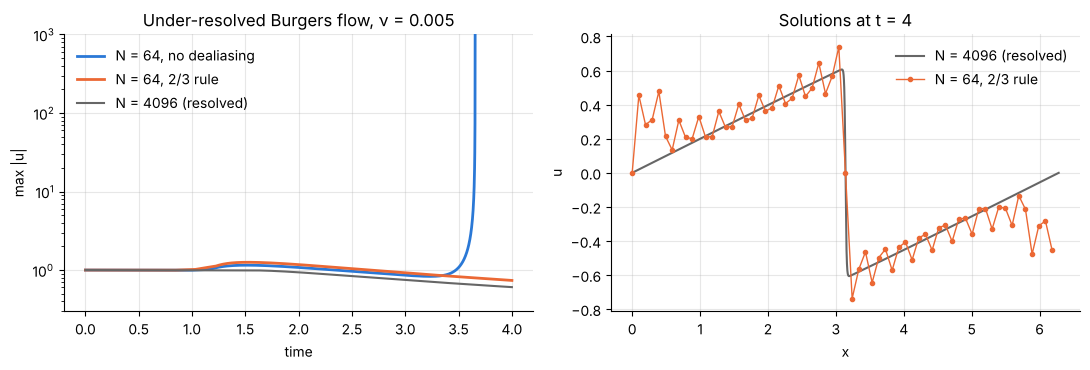

In [8]:
def burgers(N, nu, t_end, dt, dealias):
    """Integrating-factor RK4 for Burgers' equation.

    Returns the times, max |u| and the relative size of the highest retained Fourier modes at each step, and the final u.
    """
    x = 2 * np.pi * np.arange(N) / N
    k = np.fft.fftfreq(N, 1 / N)
    ik = 1j * k
    ik[N // 2] = 0
    cut = N / 3 if dealias else N / 2
    mask = (np.abs(k) < cut).astype(float) if dealias else np.ones(N)
    edge = (np.abs(k) > 0.9 * cut) & (np.abs(k) < cut)             # the highest modes in use
    E = np.exp(-nu * k**2 * dt / 2)
    E2 = E * E
    nonlinear = lambda v: -mask * fft(np.real(ifft(v)) * np.real(ifft(ik * v)))
    v = mask * fft(np.sin(x))
    times, peak, tail = [0.0], [1.0], [0.0]
    for n in range(1, round(t_end / dt) + 1):
        k1 = nonlinear(v)
        k2 = nonlinear(E * (v + dt / 2 * k1))
        k3 = nonlinear(E * v + dt / 2 * k2)
        k4 = nonlinear(E2 * v + dt * E * k3)
        v = E2 * v + dt / 6 * (E2 * k1 + 2 * E * (k2 + k3) + k4)
        times.append(n * dt)
        peak.append(np.abs(ifft(v)).max())
        tail.append(np.abs(v[edge]).max() / np.abs(v).max())
        if not peak[-1] < 1e3:                                     # stop once the run has exploded
            break
    return np.array(times), np.array(peak), np.array(tail), np.real(ifft(v))

nu_burgers = 0.005
with np.errstate(all="ignore"):
    t_alias, peak_alias, tail_alias, _ = burgers(64, nu_burgers, 4.0, 0.002, dealias=False)
t_safe, peak_safe, tail_safe, u_safe = burgers(64, nu_burgers, 4.0, 0.002, dealias=True)
t_ref, peak_ref, tail_ref, u_ref = burgers(4096, nu_burgers, 4.0, 0.001, dealias=True)        # a resolved reference
error_safe = np.abs(u_safe - u_ref[::64]).max()

print(f"N = 64 without dealiasing: stopped at t = {t_alias[-1]:.2f} with max |u| = {peak_alias[-1]:.1e}")
print(f"N = 64 with the 2/3 rule:  reached t = {t_safe[-1]:.2f}, largest |u| during the run {peak_safe.max():.2f}, error at t = 4: {error_safe:.2f}")
print(f"N = 4096 reference:        largest |u| during the run {peak_ref.max():.6f}")
print(f"highest modes relative to the largest, worst over the run: {tail_safe.max():.0e} for N = 64, {tail_ref.max():.0e} for N = 4096")
assert t_alias[-1] < 4.0 and peak_alias[-1] > 1e3                    # the aliased run blows up
assert t_safe[-1] == 4.0 and peak_safe.max() < 1.5                   # the dealiased run survives
assert peak_ref.max() < 1 + 1e-9 and tail_ref.max() < 1e-9           # the reference is resolved and obeys the bound |u| <= 1
assert error_safe > 0.02 and peak_safe.max() > 1.1                   # ... but the dealiased N = 64 run is not accurate
t_mild = burgers(64, 2 * nu_burgers, 4.0, 0.002, dealias=False)[0]
assert t_mild[-1] == 4.0                                             # with twice the viscosity the aliased run survives

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogy(t_alias, peak_alias, label="N = 64, no dealiasing")
axes[0].semilogy(t_safe, peak_safe, label="N = 64, 2/3 rule")
axes[0].semilogy(t_ref, peak_ref, color="0.4", lw=1.5, label="N = 4096 (resolved)")
axes[0].set(xlabel="time", ylabel="max |u|", ylim=(0.3, 1e3), title="Under-resolved Burgers flow, ν = 0.005")
axes[0].legend(frameon=False, loc="upper left")
x64, x_ref = 2 * np.pi * np.arange(64) / 64, 2 * np.pi * np.arange(4096) / 4096
axes[1].plot(x_ref, u_ref, color="0.4", lw=1.5, label="N = 4096 (resolved)")
axes[1].plot(x64, u_safe, "o-", ms=3, lw=1, color="C1", label="N = 64, 2/3 rule")
axes[1].set(xlabel="x", ylabel="u", title="Solutions at t = 4")
axes[1].legend(frameon=False, loc="upper right")
fig.tight_layout()

Without dealiasing the run explodes: energy that should move to wavenumbers beyond the grid is
folded back onto resolved ones, where it feeds the same process again. With the 2/3 rule the
run survives to the end. (The instability is not inevitable. With twice the viscosity the
aliased run also survives, as the last assert shows: aliasing errors are present in every
under-resolved run, and whether they grow depends on how much damping there is.)

Survival is not accuracy. The exact solution never exceeds 1 in magnitude, and the dealiased
run overshoots that bound and carries grid-scale oscillations around the front. Dealiasing
cures the **instability**. It does not cure the **under-resolution**, for which the only
remedies are those of 16.3. Other stabilizers behave the same way: a spectral filter or a
little extra viscosity keeps an under-resolved run alive, and its results should be trusted no
more than this one.

## 16.5 Rounding errors and ill-conditioning

**Problem.** Solve $u'' = f$, $u(\pm1) = 0$, with the exact solution $u = \sin 4\pi x$, using
more and more Chebyshev points.

In [9]:
N_values = np.array([16, 32, 64, 128, 256, 512, 1024])
bvp_error, condition = [], []
for N in N_values:
    D, x = cheb(N)
    D2 = (D @ D)[1:-1, 1:-1]
    u = solve(D2, -(4 * np.pi) ** 2 * np.sin(4 * np.pi * x[1:-1]))
    bvp_error.append(np.abs(u - np.sin(4 * np.pi * x[1:-1])).max())
    condition.append(np.linalg.cond(D2))
bvp_error, condition = np.array(bvp_error), np.array(condition)

print("    N      error     condition number   condition / N⁴")
for N, e, c in zip(N_values, bvp_error, condition):
    print(f"{N:5d}   {e:8.1e}   {c:14.2e}   {c / N**4:12.4f}")
cond_order = observed_order(N_values, 1 / condition)
print(f"the condition number grows like N^{cond_order:.2f}")
assert abs(cond_order - 4) < 0.05
assert bvp_error[N_values == 64][0] < 1e-12 and bvp_error[-1] > 10 * bvp_error[N_values == 64][0]

    N      error     condition number   condition / N⁴
   16    5.6e-03         1.32e+03         0.0201
   32    1.8e-12         2.08e+04         0.0198
   64    4.5e-14         3.31e+05         0.0197
  128    9.9e-14         5.29e+06         0.0197
  256    6.9e-13         8.45e+07         0.0197
  512    3.1e-12         1.35e+09         0.0197
 1024    6.3e-12         2.16e+10         0.0197
the condition number grows like N^4.00


The error reaches the rounding level at $N = 64$ and then climbs by about two orders of
magnitude, the pattern of notebook 5: truncation error falls, rounding error rises. The new
information is in the last two columns. The condition number of the second-derivative matrix
grows like $0.02\,N^4$ (and like $N^8$ for a fourth derivative), because the smallest grid
spacing is of order $N^{-2}$.

In fairness, the damage is much smaller than the condition number suggests: at $N = 1024$ the
pessimistic estimate, condition number times $10^{-16}$, is $10^{-6}$, and the actual error is
about $10^{-11}$. Chebyshev matrices are better behaved than their condition numbers. The
practical advice is still that of notebook 5. Use the $N$ the problem needs, which the
coefficient test of 16.3 reveals, and no more. For problems that do need thousands of points,
there are formulations that integrate instead of differentiating and keep the condition number
bounded; they are beyond this course.

## 16.6 The time-step restriction

**Problem.** Heat conduction in a slab, $u_t = u_{xx}$ with $u(\pm1) = 0$, on a Chebyshev grid
with explicit time stepping. Notebook 9 showed that the most negative eigenvalue of the
Chebyshev second-derivative matrix is about $-0.048\,N^4$, and that RK4 is stable only if
$\Delta t\,|\lambda| < 2.785$. Count the steps needed to reach $t = 0.5$ with $N = 32$.

In [10]:
N = 32
D, x = cheb(N)
L = (D @ D)[1:-1, 1:-1]
xi = x[1:-1]
largest = np.abs(eigvals(L)).max()
dt_limit = 2.785 / largest
initial = np.cos(np.pi * xi / 2) + 0.3 * np.sin(np.pi * xi)
exact = np.cos(np.pi * xi / 2) * np.exp(-np.pi**2 * 0.5 / 4) + 0.3 * np.sin(np.pi * xi) * np.exp(-np.pi**2 * 0.5)

def rk4_heat(n_steps, t_end=0.5):
    u, dt = initial.copy(), t_end / n_steps
    for _ in range(n_steps):
        k1 = L @ u
        k2 = L @ (u + dt / 2 * k1)
        k3 = L @ (u + dt / 2 * k2)
        k4 = L @ (u + dt * k3)
        u = u + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return u

steps_stable, steps_unstable = int(np.ceil(0.5 / (0.95 * dt_limit))), int(0.5 / (1.05 * dt_limit))
with np.errstate(all="ignore"):
    error_stable = np.abs(rk4_heat(steps_stable) - exact).max()
    error_unstable = np.abs(rk4_heat(steps_unstable) - exact).max()

print(f"N = {N}: largest eigenvalue {largest:.3e} = {largest / N**4:.4f} N⁴, so RK4 needs dt < {dt_limit:.2e}")
print(f"RK4, dt 5 % below the limit: {steps_stable:5d} steps, error {error_stable:.1e}")
print(f"RK4, dt 5 % above the limit: {steps_unstable:5d} steps, error {error_unstable:.1e}")
assert abs(largest / N**4 - 0.048) < 0.002
assert error_stable < 1e-10 and not error_unstable < 1.0

N = 32: largest eigenvalue 4.994e+04 = 0.0476 N⁴, so RK4 needs dt < 5.58e-05
RK4, dt 5 % below the limit:  9438 steps, error 5.2e-15
RK4, dt 5 % above the limit:  8538 steps, error nan


Explicit RK4 takes more than nine thousand steps, and blows up if the step is five per cent
larger. The limit has nothing to do with accuracy: the solution here is two slowly decaying
modes. It comes from the fastest mode the **grid** can represent, which lives in the tightly
clustered points next to the walls. Doubling $N$ multiplies the number of steps by 16.

The fixes are those of notebooks 9 and 11: an implicit method such as Crank–Nicolson, which is
stable for any step, or, for a stiff linear part, the matrix exponential, an integrating
factor or exponential time differencing. Advection terms are milder: their limit is
$O(N^{-2})$ on a Chebyshev grid and $O(N^{-1})$ on a Fourier grid, and explicit methods are
normally used.

## 16.7 Corner singularities

**Problem.** Fully developed laminar flow in a square duct (notebook 6):
$\nabla^2 u = -1$ on $[-1, 1]^2$ with $u = 0$ on the walls. The data are as smooth as data can
be, a constant right-hand side and zero boundary values. Is the convergence geometric?

**By hand.** At a corner the two wall conditions $u = 0$ along $x = 1$ and along $y = 1$ imply
$u_{xx} = 0$ and $u_{yy} = 0$ there, so $\nabla^2 u = 0$ at the corner. The equation demands
$-1$. No smooth function can satisfy both, and the true solution contains a term proportional
to $r^2\log r$ in the distance $r$ from each corner: its second derivatives are unbounded.
The singularity is weak, since $u$ and its gradient are continuous, but it is there.

The exact solution is a Fourier series (the terms are odd $n$ only):

$$u = \frac{1 - x^2}{2} - \frac{16}{\pi^3}\sum_{n\ \text{odd}} \frac{(-1)^{(n-1)/2}}{n^3}\,
\frac{\cosh(n\pi y/2)}{\cosh(n\pi/2)}\,\cos\frac{n\pi x}{2},\qquad
Q = \iint u\,dx\,dy = \frac43 - \frac{256}{\pi^5}\sum_{n\ \text{odd}} \frac{\tanh(n\pi/2)}{n^5} .$$

exact values: Q = 0.5623081, centre velocity = 0.2946854
whole field (largest error) : observed order   4.1   (fitted for N <= 24)
flow rate Q                 : observed order   8.0   (fitted for N <= 24)
centre velocity             : observed order   9.7   (fitted for N <= 24)
centre velocity, order between successive N up to 24: [ 9.4  8.  11.6 11.4]     error at N = 32: 4e-14


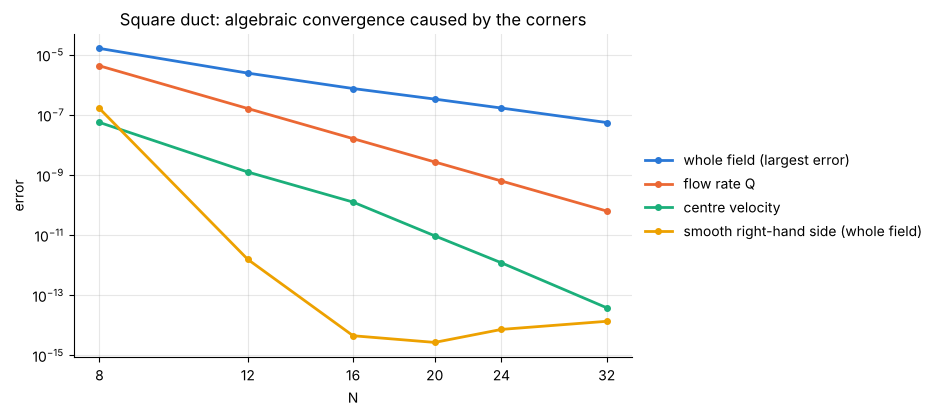

In [11]:
n_odd = np.arange(1, 4001, 2)
sign = (-1.0) ** ((n_odd - 1) // 2)

def duct_exact(x, y):
    """Series solution at the points (x_i, y_j); the ratio of cosh functions is written with decaying exponentials."""
    a = n_odd * np.pi / 2
    ratio = np.exp(np.outer(np.abs(y) - 1, a)) * (1 + np.exp(-2 * np.outer(np.abs(y), a))) / (1 + np.exp(-2 * a))
    return (1 - x[:, None] ** 2) / 2 - 16 / np.pi**3 * (np.cos(np.outer(x, a)) * sign / n_odd**3) @ ratio.T

Q_exact = 4 / 3 - 256 / np.pi**5 * np.sum(np.tanh(n_odd * np.pi / 2) / n_odd**5)
centre_exact = duct_exact(np.zeros(1), np.zeros(1))[0, 0]

duct_N = np.array([8, 12, 16, 20, 24, 32])
errors = {"whole field (largest error)": [], "flow rate Q": [], "centre velocity": [], "smooth right-hand side (whole field)": []}
for N in duct_N:
    D, x = cheb(N)
    D2, identity = (D @ D)[1:-1, 1:-1], np.eye(N - 1)
    laplacian = np.kron(identity, D2) + np.kron(D2, identity)
    u = solve(laplacian, -np.ones((N - 1) ** 2)).reshape(N - 1, N - 1)
    weights = clenshaw_curtis(N)[1][1:-1]
    errors["whole field (largest error)"].append(np.abs(u - duct_exact(x[1:-1], x[1:-1])).max())
    errors["flow rate Q"].append(abs(weights @ u @ weights - Q_exact))
    errors["centre velocity"].append(abs(u[N // 2 - 1, N // 2 - 1] - centre_exact))
    smooth = np.outer(np.cos(np.pi * x[1:-1] / 2), np.cos(np.pi * x[1:-1] / 2))      # exact solution of a smooth problem
    u_smooth = solve(laplacian, (-np.pi**2 / 2 * smooth).ravel()).reshape(N - 1, N - 1)
    errors["smooth right-hand side (whole field)"].append(np.abs(u_smooth - smooth).max())

print(f"exact values: Q = {Q_exact:.7f}, centre velocity = {centre_exact:.7f}")
above_rounding = duct_N <= 24                                # at N = 32 the centre value has reached the rounding level
orders = {name: observed_order(duct_N[above_rounding], np.array(e)[above_rounding]) for name, e in errors.items() if "smooth" not in name}
local = np.log(np.array(errors["centre velocity"])[:4] / np.array(errors["centre velocity"])[1:5]) / np.log(duct_N[1:5] / duct_N[:4])
for name, order in orders.items():
    print(f"{name:28s}: observed order {order:5.1f}   (fitted for N <= 24)")
print(f"centre velocity, order between successive N up to 24: {np.round(local, 1)}     error at N = 32: {errors['centre velocity'][-1]:.0e}")
assert abs(Q_exact - 0.562308) < 1e-6 and abs(centre_exact - 0.294685) < 1e-6
assert abs(orders["whole field (largest error)"] - 4) < 0.5 and abs(orders["flow rate Q"] - 8) < 0.3
assert local.min() > 7.5 and local.max() < 13 and errors["centre velocity"][-1] < 1e-12       # faster than Q, with no single power
assert errors["smooth right-hand side (whole field)"][2] < 1e-12 and errors["whole field (largest error)"][2] > 1e-7

fig, ax = plt.subplots(figsize=(7.2, 4.2))
for name, e in errors.items():
    ax.loglog(duct_N, np.maximum(e, 1e-16), "o-", ms=4, label=name)
ax.set(xlabel="N", ylabel="error", xticks=duct_N, xticklabels=duct_N, title="Square duct: algebraic convergence caused by the corners")
ax.minorticks_off()
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

On these logarithmic axes the largest error over the grid and the error of the flow rate are
straight lines: **algebraic** convergence, like $N^{-4}$ and $N^{-8}$. A problem with a smooth
solution on the same grids (the fourth curve) is at rounding level by $N = 16$.

Whether this matters depends on what is wanted. Quantities dominated by the interior converge
much faster than the field does near the corners. The flow rate gains eight powers of $N$, and
the centre velocity converges faster still, between $N^{-8}$ and $N^{-12}$ with no single
power, until rounding takes over near $N = 32$. With $N = 16$ the flow rate already has
almost eight digits and the centre velocity more than nine. Notebook 6 could quote the
friction factor to many digits for this reason. Quantities **at** the corners, such
as the wall shear stress close to a corner or second derivatives of the solution, converge
slowly, and stress concentrations at re-entrant corners (an L-shaped domain, a crack tip),
where the solution behaves like $r^{2/3}$ or $r^{1/2}$, are much worse. For those, the
singular term must be subtracted analytically or the mesh refined towards the corner with
elements.

## 16.8 Eigenvalues that the grid cannot resolve

No new demonstration is needed, because notebook 8 gave it. A matrix of size $N - 1$ has
$N - 1$ eigenvalues, and only the lower ones approximate eigenvalues of the differential
operator. For $u'' = \lambda u$ with $N = 36$, the lowest 18 were correct to four digits and
the last ones were wrong by factors of ten or more. The matrix does not mark the bad ones:
they are perfectly good eigenvalues of the matrix, whose eigenvectors oscillate too fast for
the grid to represent a mode of the differential equation.

The test, from notebook 8: compute with two values of $N$ and keep only the eigenvalues that
agree. It matters most in stability calculations (notebooks 14 and 17), where an unresolved
eigenvalue in the wrong half-plane would announce an instability that does not exist. Never
report an eigenvalue from a single resolution.

## 16.9 Bookkeeping mistakes: smooth, plausible and wrong

The failures so far announce themselves with wiggles, overflow or stalled convergence. The
most dangerous mistakes do not: the program runs, the plot is smooth, the numbers are wrong.
Spectral codes offer several opportunities.

**Mistake 1: the Chebyshev grid runs from right to left.** A tube is fed at $x = -1$ with a
solution of concentration 1, and the concentration is held at 0 at the outlet $x = 1$:
$c'' - Pe\,c' = 0$ with $Pe = 5$. The exact profile is
$c = (e^{Pe\,x} - e^{Pe})/(e^{-Pe} - e^{Pe})$. In the code below, the "wrong" version sets the
inlet value in row 0, as one would on a grid that runs from left to right. On the Chebyshev
grid row 0 is $x = +1$.

In [12]:
Pe, N = 5.0, 24
D, x = cheb(N)
operator = D @ D - Pe * D

def tube(inlet_row, outlet_row):
    A, b = operator.copy(), np.zeros(N + 1)
    A[inlet_row, :], A[inlet_row, inlet_row], b[inlet_row] = 0, 1, 1.0       # c = 1 at the inlet
    A[outlet_row, :], A[outlet_row, outlet_row], b[outlet_row] = 0, 1, 0.0   # c = 0 at the outlet
    return solve(A, b)

c_exact = (np.exp(Pe * x) - np.exp(Pe)) / (np.exp(-Pe) - np.exp(Pe))
c_wrong, c_right = tube(0, N), tube(N, 0)                 # index N is x = -1, index 0 is x = +1
weights = clenshaw_curtis(N)[1]
print(f"mean concentration: wrong rows {weights @ c_wrong / 2:.4f}, right rows {weights @ c_right / 2:.4f}, exact {np.exp(Pe) / (2 * np.sinh(Pe)) - 1 / (2 * Pe):.4f}")
print(f"the check: c at x = {x[N]:+.0f} is {c_wrong[N]:.1f} in the wrong version and {c_right[N]:.1f} in the right one")
assert np.abs(c_right - c_exact).max() < 1e-10 and np.abs(c_wrong - c_exact).max() > 0.9
assert x[0] == 1.0 and x[N] == -1.0

mean concentration: wrong rows 0.1000, right rows 0.9000, exact 0.9000
the check: c at x = -1 is 0.0 in the wrong version and 1.0 in the right one


**Mistake 2: wavenumbers for a domain that is not $2\pi$ long.** A signal is sampled over a
period $L = 0.4$ and differentiated with `fft_derivative`, which assumes a period of $2\pi$.
The correct wavenumbers are $2\pi k/L$, so each derivative needs a factor $2\pi/L$.

test on sin(2πt/L): computed derivative / exact derivative at t = 0 is 0.0637 (should be 1; L/2π = 0.0637)


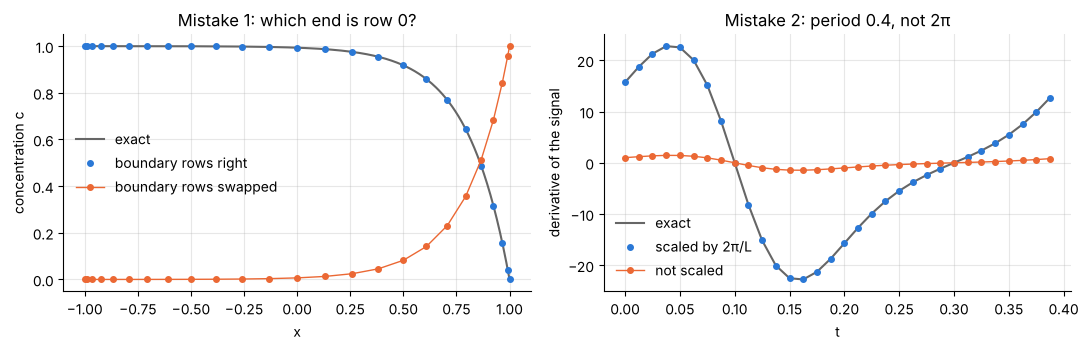

In [13]:
L_period, N = 0.4, 32
t = L_period * np.arange(N) / N
signal = np.exp(np.sin(2 * np.pi * t / L_period))
rate_exact = 2 * np.pi / L_period * np.cos(2 * np.pi * t / L_period) * signal
rate_wrong = fft_derivative(signal)
rate_right = fft_derivative(signal) * 2 * np.pi / L_period

# the check that catches it: differentiate a function whose derivative is known
test = np.sin(2 * np.pi * t / L_period)
ratio = fft_derivative(test)[0] / (2 * np.pi / L_period)
print(f"test on sin(2πt/L): computed derivative / exact derivative at t = 0 is {ratio:.4f} (should be 1; L/2π = {L_period / (2 * np.pi):.4f})")
assert np.abs(rate_right - rate_exact).max() < 1e-10
assert np.allclose(rate_wrong, rate_exact * L_period / (2 * np.pi))       # wrong by the constant factor L/2π

fine = np.linspace(-1, 1, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(fine, (np.exp(Pe * fine) - np.exp(Pe)) / (np.exp(-Pe) - np.exp(Pe)), color="0.4", lw=1.5, label="exact")
axes[0].plot(x, c_right, "o", ms=4, label="boundary rows right")
axes[0].plot(x, c_wrong, "o-", ms=4, lw=1, label="boundary rows swapped")
axes[0].set(xlabel="x", ylabel="concentration c", title="Mistake 1: which end is row 0?")
axes[0].legend(frameon=False, loc="center left")
axes[1].plot(t, rate_exact, color="0.4", lw=1.5, label="exact")
axes[1].plot(t, rate_right, "o", ms=4, label="scaled by 2π/L")
axes[1].plot(t, rate_wrong, "o-", ms=4, lw=1, label="not scaled")
axes[1].set(xlabel="t", ylabel="derivative of the signal", title="Mistake 2: period 0.4, not 2π")
axes[1].legend(frameon=False, loc="lower left")
fig.tight_layout()

Both wrong answers are smooth and look reasonable. The swapped tube is a legitimate solution
of a different problem (flow in the other direction), with a mean concentration of 0.1 where
0.9 is correct. The unscaled derivative has exactly the right shape and is about sixteen times
too small.

The defence is the same in every case: **before solving the real problem, apply each building
block to a function with a known answer.** One line each.

| Mistake | What goes wrong | One-line check |
| --- | --- | --- |
| index 0 taken for $x = -1$ on a Chebyshev grid | boundary conditions applied at the wrong ends | `print(x[0], x[-1])`, and print the solution at both ends |
| period $L \ne 2\pi$, wavenumbers not scaled by $2\pi/L$ | derivatives wrong by a constant factor | differentiate $\sin(2\pi x/L)$ |
| interval $[a, b]$, matrix not scaled by $2/(b - a)$ | the same, for Chebyshev | differentiate $x$ and $x^2$ |
| Nyquist mode kept in an odd derivative | a spurious sawtooth, or a complex result silently truncated | differentiate $\cos(Nx/2)$: the answer must be 0 on the grid, before any `np.real` is applied |
| a test such as `x > 0` at a grid point meant to be exactly 0 | $\cos(\pi/2) = 6\times10^{-17}$: the point falls on the wrong side (16.1) | `print(x[N // 2])` |
| `fftshift` applied to the data but not to the wavenumbers (or the reverse) | each coefficient multiplied by the wrong $k$: smooth garbage | differentiate $\sin 3x$ |
| points and matrices ordered differently in a 2D Kronecker product | $x$ and $y$ derivatives exchanged | apply the operator to $x^2 y$ |

## 16.10 Which method for which problem?

| | Spectral (global) | Finite differences | Finite elements, finite volumes |
| --- | --- | --- | --- |
| Geometry | box, disk, periodic cell | simple, or mapped grids | arbitrary |
| Smooth solution | geometric convergence: 10 digits from tens of points | algebraic: $N^{-2}$ to $N^{-6}$ | algebraic, order set by the element |
| Kinks, shocks, interfaces | algebraic at best, Gibbs oscillations | robust with suitable schemes | robust, mesh can follow the feature |
| Thin layers | good at the walls (Chebyshev), poor inside | need local refinement | local refinement is natural |
| Matrices | dense, ill-conditioned, small | sparse, large | sparse, large |
| Explicit time step | severe on Chebyshev grids ($N^{-2}$, $N^{-4}$) | $h$, $h^2$ | $h$, $h^2$ |
| Programming effort | very low for simple domains | low | high, usually a library or package |
| Typical use | stability and eigenvalue problems, turbulence in simple domains, benchmarks, model problems | general-purpose, structured grids | industrial analysis of real parts |

In short: choose a spectral method when the solution is smooth, the domain is simple, and
accuracy matters, or when a problem must be solved so many times that a small matrix is worth
having. When the geometry is complicated, the solution is rough, or two or three digits are
enough, use a low-order method without regret.

**Geometry** is the first row of the table for a reason. Every method in this course lives on
an interval, a periodic interval or a product of those: boxes, periodic cells, disks and
cylinders (notebook 12). A pipe elbow, a turbine blade or a bracket with holes is none of
these. Smooth mappings extend the range a little (an ellipse, a wavy channel). Beyond that the
answer is the idea of 16.1, taken further: divide the domain into many quadrilateral pieces,
use a tensor-product Chebyshev or Legendre grid on each, and join them by continuity. This is
the **spectral element method**, which combines the geometric flexibility of finite elements
with high-order accuracy inside each element, at a large cost in programming effort.

## 16.11 A debugging checklist

When a spectral computation misbehaves, ask these questions in this order. The early ones are
cheap and catch the most common faults.

1. **Does each building block pass a test with a known answer?** Differentiate a polynomial or
   a sine with every matrix and every FFT routine, on the actual interval (16.9).
2. **Are the boundary conditions applied at the ends you think?** Print the grid and the
   solution at both ends (16.9).
3. **Does the method reproduce an exact solution of the same equation?** If none is known,
   manufacture one: choose $u$, compute the right-hand side it needs, and solve.
4. **Is the solution resolved?** Look at the last Chebyshev or Fourier coefficients. If they
   have not fallen to a small fraction of the largest, nothing else is worth checking (16.3).
5. **Does the answer change when $N$ changes?** Compare two resolutions, for the solution and
   for every eigenvalue you intend to report (16.8). Is the convergence geometric? If it is
   algebraic, look for a kink, a jump, a corner or a non-periodic function (16.1, 16.2, 16.7).
6. **Is $N$ larger than it needs to be?** If the error grows with $N$, rounding has taken
   over: reduce $N$ (16.5).
7. **For time-dependent problems: is the time step inside the stability limit?** Compare
   $\Delta t$ times the largest eigenvalue of the spatial operator with the stability region,
   and halve $\Delta t$ to see whether the result changes (16.6).
8. **For nonlinear problems: is the nonlinear term dealiased, and are the invariants
   conserved?** A drifting invariant or a slow pile-up at the highest wavenumbers points to
   aliasing (16.4, and 15.6 of notebook 15 for the invariants).

## Summary

- Spectral accuracy is a property of smooth solutions on simple domains. A jump, a kink, a
  corner or a false assumption of periodicity reduces the convergence to algebraic.
- Splitting the domain where the solution is not smooth restores geometric convergence. Taken
  to its conclusion this is the spectral element method.
- The tail of the coefficients tells whether a computation is resolved. Stabilizing an
  under-resolved run (by dealiasing or filtering) keeps it alive and does not make it accurate.
- Chebyshev grids pay for their accuracy with ill-conditioned matrices and severe explicit
  time-step limits. Use moderate $N$ and implicit or exponential time stepping.
- The quiet mistakes are the dangerous ones. Test every building block on a known function,
  and never trust a result from a single resolution.

## Exercises

1. **A composite wall.** Steady conduction with heat generation in a wall made of two
   materials: $(k\,u')' = -1$ on $[-1, 1]$ with $k = 1$ for $x < 0$ and $k = 10$ for $x > 0$,
   and $u(\pm1) = 0$. At the interface $u$ and the heat flux $k\,u'$ are continuous. (a) Derive
   the exact solution, which is a different parabola on each side. (b) Adapt `rod_two_elements`
   to this problem, with the interface condition on the flux, and show that it is exact to
   rounding with $N = 4$. (c) Explain why a single Chebyshev grid applied to $k\,u'' = -1$
   with $k$ sampled at the grid points cannot give the right answer, however large $N$ is.
2. **Choosing N without an exact solution.** Reaction and diffusion in a catalyst slab with a
   large Thiele modulus $1/\varepsilon$ (notebook 6): $\varepsilon^2 u'' - u = -1$,
   $u(\pm1) = 0$, with boundary layers of thickness $\varepsilon$ at both walls. For
   $\varepsilon = 0.1, 0.03, 0.01, 0.003$ find the smallest even $N$ for which the last three
   Chebyshev coefficients of the computed solution are below $10^{-8}$ times the largest one.
   Confirm with the exact solution, written in a form that does not overflow,
   $u = 1 - e^{-(1 - |x|)/\varepsilon}\,\dfrac{1 + e^{-2|x|/\varepsilon}}{1 + e^{-2/\varepsilon}}$,
   that the true error is then below $10^{-8}$. Fit $N \propto \varepsilon^{-p}$, compare $p$
   with 16.3, and use the fit to predict the $N$ needed for $\varepsilon = 0.001$. Check the
   prediction.
3. **A filter in place of the 2/3 rule.** In `burgers`, replace the mask by the smooth filter
   $\sigma(k) = \exp\!\big[-36\,(2|k|/N)^{8}\big]$, applied to the solution $\hat u$ at the end
   of every time step (and no mask on the nonlinear term). Run the case of 16.4 ($N = 64$,
   $\nu = 0.005$, $\Delta t = 0.002$, $t = 4$). Does the run survive? Compare its largest
   value of $|u|$ during the run, and its largest and root-mean-square errors at $t = 4$
   against the $N = 4096$ reference, with those of the 2/3 rule.
4. **Wall shear stress in the square duct.** Differentiating the series of 16.7 gives the
   velocity gradient on the wall $x = 1$:
   $\dfrac{\partial u}{\partial x}(1, y) = -1 + \dfrac{8}{\pi^2}\displaystyle\sum_{n\ \text{odd}} \dfrac{\cosh(n\pi y/2)}{n^2\cosh(n\pi/2)}$,
   which equals $-0.675314$ at the middle of the wall and tends to 0 at the corners. For
   $N = 8, 12, 16, 24, 32$ compute the gradient from the Chebyshev solution at the interior
   grid points $y_j$ of the wall, by applying the first row of `cheb(N)[0]` in the $x$
   direction (remember that $u = 0$ on the walls). Sum the series with 20 000 terms, writing
   the ratio of cosh functions with decaying exponentials as in `duct_exact`. Measure the
   order of convergence (a) at the middle of the wall and (b) of the largest error along the
   wall. Explain the difference, and relate it to 16.7.
5. **Find the two mistakes.** The following lines are meant to solve
   $u'' = -\pi^2\sin(\pi x)$ on $[0, 1]$ with $u(0) = 0$ and $u'(1) = -\pi$, whose solution is
   $u = \sin\pi x$. They run without error and return a smooth curve that is wrong. Find both
   mistakes with the checks of 16.9, correct them, and confirm an error below $10^{-10}$.

   ```python
   N = 24
   D, xi = cheb(N)
   x = (xi + 1) / 2                             # map [-1, 1] to [0, 1]
   A = D @ D
   b = -np.pi**2 * np.sin(np.pi * x)
   A[0, :] = 0; A[0, 0] = 1; b[0] = 0           # u(0) = 0
   A[N, :] = D[N, :]; b[N] = -np.pi             # u'(1) = -π
   u = np.linalg.solve(A, b)
   ```